# 03. 추론의 흐름 — v1에서 3.5까지 한 표로

TabPFN은 학습한 모델을 한 번만 forward하지 않습니다. 사용자의 표를 여러 방식으로 전처리한 "앙상블 멤버"를 만들고, 멤버마다 forward한 뒤 예측을 평균합니다. 이 노트북은 [01 모델 구조](01_architecture_evolution.ipynb)·[02 prior](02_prior_evolution.ipynb)처럼 축 하나만 따라갑니다. 버전마다 멤버를 몇 개, 어떤 전처리로 만드는지 보고, 같은 열이 멤버 종류마다 어떻게 바뀌는지, 실제 데이터셋에서 멤버 수와 종류가 점수를 얼마나 바꾸는지를 Hub에 있는 v1·v2 가중치로 잽니다.

흐름은 이렇습니다. v1은 클래스 번호와 feature 순서를 돌린 멤버 32개를 쓰고, 절반에 Yeo-Johnson 변환을 했습니다. v2는 멤버를 분류 4개·회귀 8개로 줄이는 대신 분위수 변환(+SVD)과 Yeo-Johnson을 번갈아 쓰고, feature 순서 섞기와 샘플 식별자 열을 더했습니다. 2.5는 Yeo-Johnson 자리에 robust scaling + soft clipping을 넣었고, 3도 그것을 이어 씁니다. 3.5는 전처리를 standard 하나로 줄였습니다. 셀 encoder가 열 안의 순위(ECDF)를 직접 보게 되었기 때문으로 보입니다.

각 칸의 자세한 설명은 [노트북 로드맵의 축별로 보기 표](../README.md#축별로-보기)의 추론 줄에서 이어지는 노트북에 있습니다.

다루는 흐름:

1. 버전마다 무엇을 쓰나 — 멤버 수와 멤버 종류
2. 열 하나가 멤버 종류마다 어떻게 바뀌나
3. 멤버가 하는 나머지 일 — 열 순서, 클래스 번호, 식별자 열
4. 실제 데이터셋에서 — 멤버 수와 종류가 점수를 얼마나 바꾸나
5. 정리

## `minipfn` 불러오기

다른 노트북과 같은 import shim입니다. 이 노트북은 `notebooks/axes/` 아래에 있으므로 저장소 루트는 두 단계 위입니다. 4절은 Hub에서 v1·v2 분류 가중치(`aiden-jeon/minipfn-tabpfn-v1`, `aiden-jeon/minipfn-tabpfn-v2-classifier`)를 받습니다.

In [1]:
try:
    import minipfn
except ImportError:
    import sys
    from pathlib import Path

    sys.path.insert(0, str(Path.cwd().parents[1] / "src"))
    import minipfn

In [2]:
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.datasets import load_breast_cancer, load_wine
from sklearn.metrics import log_loss
from sklearn.model_selection import train_test_split

from minipfn import TabPFNv1Classifier, TabPFNv2Classifier, set_seed
from minipfn.inference import ensemble
from minipfn.inference.preprocessing import OUTLIER_SIGMA, Member, MemberPreprocessor
from minipfn.recipes import tabpfn_v1, tabpfn_v2, tabpfn_v3

set_seed(0)  # 재현성을 위해 난수 시드를 고정한다.
warnings.filterwarnings("ignore", category=UserWarning)  # sklearn 변환기의 경고

## 1. 버전마다 무엇을 쓰나 — 멤버 수와 멤버 종류

recipe에 적힌 추론 기본값을 그대로 꺼냅니다. v1은 `recipes/tabpfn_v1.py`의 `N_ENSEMBLE`·`SOFTMAX_TEMPERATURE`, v2·2.5는 `recipes/tabpfn_v2.py`의 `N_ESTIMATORS`·`MEMBER_KIND_PRESETS`, 3·3.5는 `recipes/tabpfn_v3.py`의 `INFERENCE`입니다. v2부터는 `minipfn/inference/ensemble.py`가 멤버를 만들고, 온도는 모두 `ensemble.SOFTMAX_TEMPERATURE`입니다.

In [3]:
def kinds_text(kinds):
    return " + ".join(kinds)


inference_table = {
    "v1": {
        "멤버 수 (분류·회귀)": f"{tabpfn_v1.N_ENSEMBLE} · —",
        "멤버 전처리": "그대로 / Yeo-Johnson 번갈아",
        "멤버마다 바꾸는 것": "클래스 번호 회전, feature 순서 회전",
        "softmax 온도": tabpfn_v1.SOFTMAX_TEMPERATURE,
    }
}
v2_counts = tabpfn_v2.N_ESTIMATORS
for name in ["v2", "v2.5"]:
    inference_table[name] = {
        "멤버 수 (분류·회귀)": f"{v2_counts['classification']} · {v2_counts['regression']}",
        "멤버 전처리": kinds_text(tabpfn_v2.MEMBER_KIND_PRESETS[name]),
        "멤버마다 바꾸는 것": "feature 순서 섞기, 클래스 번호 섞기, 식별자 열",
        "softmax 온도": ensemble.SOFTMAX_TEMPERATURE,
    }
for name in ["v3", "v3.5"]:
    preset = tabpfn_v3.INFERENCE[name]
    counts = preset["n_estimators"]
    inference_table[name] = {
        "멤버 수 (분류·회귀)": f"{counts['classification']} · {counts['regression']}",
        "멤버 전처리": kinds_text(preset["member_kinds"]),
        "멤버마다 바꾸는 것": "feature 순서 섞기, 클래스 번호 섞기, 식별자 열",
        "softmax 온도": ensemble.SOFTMAX_TEMPERATURE,
    }
display(pd.DataFrame(inference_table).T)

,멤버 수 (분류·회귀),멤버 전처리,멤버마다 바꾸는 것,softmax 온도
v1,32 · —,그대로 / Yeo-Johnson 번갈아,"클래스 번호 회전, feature 순서 회전",0.8
v2,4 · 8,quantile + power,"feature 순서 섞기, 클래스 번호 섞기, 식별자 열",0.9
v2.5,4 · 8,quantile + robust,"feature 순서 섞기, 클래스 번호 섞기, 식별자 열",0.9
v3,4 · 8,quantile + robust,"feature 순서 섞기, 클래스 번호 섞기, 식별자 열",0.9
v3.5,8 · 8,standard,"feature 순서 섞기, 클래스 번호 섞기, 식별자 열",0.9


멤버 수는 v1의 32개에서 v2의 4·8개로 크게 줄고, 그 뒤로는 3.5가 분류를 8개로 늘린 것 말고는 그대로입니다. 바뀌는 것은 주로 멤버 전처리입니다. 2.5 논문은 robust scaling과 soft clipping을 넣었다고만 적어서, 이 저장소는 RealMLP의 방식(열마다 중앙값을 빼고 사분위 폭으로 나눈 뒤 $x / \sqrt{1 + (x/3)^2}$)으로 구현했고 Yeo-Johnson 자리에 넣었습니다(`MEMBER_KINDS_V2_5`). 회귀는 멤버 절반에서 target에도 Yeo-Johnson을 합니다(v2부터).

## 2. 열 하나가 멤버 종류마다 어떻게 바뀌나

"집에서 역까지 걸리는 시간(분)" 열을 만듭니다. 대부분 5~30분이지만 오른쪽 꼬리가 길고, 한 명이 240분으로 잘못 적었습니다. 이 열 하나를 멤버 종류마다 학습 행에 맞춰(`MemberPreprocessor.fit`) 변환합니다. 모든 멤버는 먼저 평균에서 표준편차 12배 밖의 값을 그 경계로 자르고(`OUTLIER_SIGMA`), 그다음 종류별 변환을 합니다. standard 멤버는 값을 그대로 두고, 표준화는 모델이 안에서 합니다.

In [4]:
rng = np.random.default_rng(0)
minutes = np.round(np.exp(rng.normal(np.log(12), 0.6, 199)), 1)
minutes = np.append(minutes, 240.0)  # 잘못 적은 값 하나
column = minutes[:, None]

KINDS = ["quantile", "power", "robust", "standard"]
transformed = {"원래 값": minutes}
for kind in KINDS:
    pre = MemberPreprocessor(Member(kind, None, False, 0), [], 100).fit(column)
    clipped = np.clip(column, pre.lower, pre.upper)  # 평균 ± 12σ 밖은 경계로
    values = clipped if pre.transformer is None else pre.transformer.transform(clipped)
    transformed[kind] = values[:, 0]
print(f"자르는 경계: 평균 ± {OUTLIER_SIGMA:.0f}σ = {pre.lower[0]:.1f} ~ {pre.upper[0]:.1f}분")

order = np.argsort(minutes)
picks = {"가장 짧음": order[0], "중앙값": order[100], "상위 10%": order[180], "상위 1%": order[197]}
picks["240분 (잘못 적음)"] = order[-1]
table = pd.DataFrame(transformed).iloc[list(picks.values())]
table.index = list(picks)
display(table.round(3))

z_of_outlier = {k: (v[-1] - v.mean()) / v.std() for k, v in transformed.items()}
print(
    "240분 행이 열 안에서 몇 σ 떨어져 있나:",
    {k: round(float(v), 1) for k, v in z_of_outlier.items()},
)

자르는 경계: 평균 ± 12σ = -198.7 ~ 229.3분


,원래 값,quantile,power,robust,standard
가장 짧음,2.8,0.000,-2.552,-0.916,2.800
중앙값,12.4,0.512,0.054,0.005,12.400
상위 10%,26.9,0.899,1.281,1.317,26.900
상위 1%,38.9,0.949,1.814,1.997,38.900
240분 (잘못 적음),240.0,1.000,3.916,2.972,229.323


240분 행이 열 안에서 몇 σ 떨어져 있나: {'원래 값': 12.6, 'quantile': 1.7, 'power': 3.9, 'robust': 3.8, 'standard': 12.5}


240분은 평균 ± 12σ 경계(229분쯤) 바로 밖이라 standard 멤버에서는 229분으로만 잘립니다. 표준화하면 여전히 평균에서 12σ쯤 떨어져 있어서, 모델 안에서 다른 199행이 좁은 곳에 몰립니다. 다른 세 종류는 이 행을 끌어당깁니다.

- **quantile**: 순위로 바꿔 [0, 1]에 고르게 폅니다. 240분은 1.0, 상위 1%는 0.95쯤입니다. 이상치와 꼬리가 거의 같은 값이 되는 대신, 순위 사이의 간격 정보는 잃습니다. 그래서 이 멤버는 원래 열도 옆에 그대로 붙입니다.
- **power (Yeo-Johnson)**: 로그에 가까운 변환을 학습 행에 맞춰 골라 꼬리를 줄입니다. 240분이 4σ 아래로 들어옵니다.
- **robust + soft clip**: 중앙값과 사분위 폭으로 맞춘 뒤 $\pm 3$ 근처에서 부드럽게 눌러, 240분이 3에 바짝 붙습니다. Yeo-Johnson과 달리 꼬리 쪽 순서와 간격을 그대로 두면서 끝만 누릅니다.

변환 전후를 그래프로 그리면 세 종류가 꼬리를 누르는 모양이 보입니다.

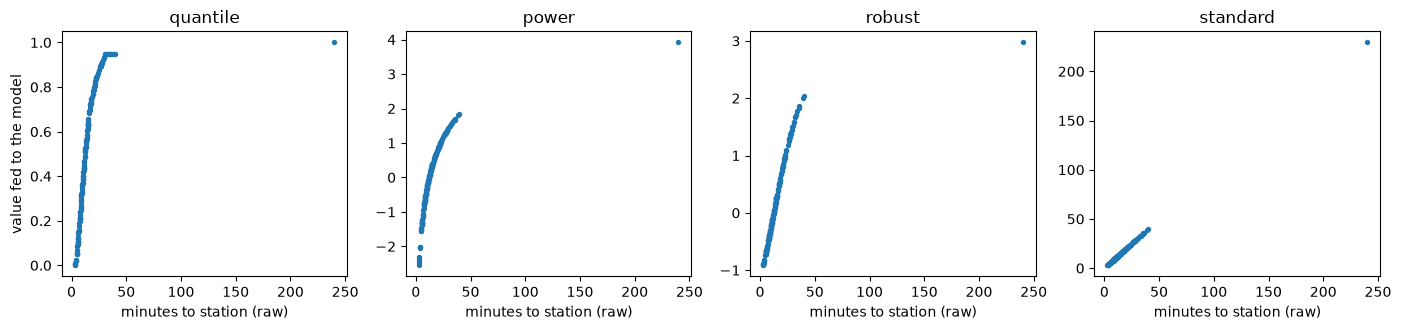

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.4), sharex=True)
for ax, kind in zip(axes, KINDS, strict=True):
    ax.scatter(minutes, transformed[kind], s=8)
    ax.set_title(kind)
    ax.set_xlabel("minutes to station (raw)")
axes[0].set_ylabel("value fed to the model")
plt.tight_layout()
plt.show()

v1의 멤버는 이 가운데 그대로(standard)와 Yeo-Johnson 두 가지였고, 모든 멤버에서 학습 행으로 표준화한 뒤 이상치를 누르는 단계를 따로 거쳤습니다(`inference/rotation_ensemble.py`의 `_Preprocessor`).

## 3. 멤버가 하는 나머지 일 — 열 순서, 클래스 번호, 식별자 열

v2부터의 멤버는 열 값만 바꾸지 않습니다. breast cancer 데이터(feature 30개)의 학습 행에 멤버 종류마다 전처리를 맞추고, 모델에 들어가는 열 수를 셉니다.

In [6]:
x_bc, y_bc = load_breast_cancer(return_X_y=True)
x_tr_bc, _, _, _ = train_test_split(x_bc, y_bc, test_size=0.5, random_state=0, stratify=y_bc)
width_rows = {}
for kind in KINDS:
    pre = MemberPreprocessor(Member(kind, None, False, 0), [], 500).fit(x_tr_bc)
    out = pre.transform(x_tr_bc, np.random.default_rng(0))
    n_svd = 0 if pre.svd is None else pre.svd.n_components
    width_rows[kind] = {
        "원래 열": x_tr_bc.shape[1],
        "변환한 열": out.shape[1] - n_svd - 1,
        "SVD 성분": n_svd,
        "식별자 열": 1,
        "모델에 들어가는 열": out.shape[1],
        "열 순서 (앞 8개)": str(pre.order[:8].tolist()),
    }
display(pd.DataFrame(width_rows).T)

,원래 열,변환한 열,SVD 성분,식별자 열,모델에 들어가는 열,열 순서 (앞 8개)
quantile,30,60,15,1,76,"[5, 64, 61, 16, 58, 39, 35, 71]"
power,30,30,0,1,31,"[2, 11, 25, 21, 10, 4, 29, 16]"
robust,30,30,0,1,31,"[2, 11, 25, 21, 10, 4, 29, 16]"
standard,30,30,0,1,31,"[2, 11, 25, 21, 10, 4, 29, 16]"


quantile 멤버는 원래 열 30개와 분위수 열 30개를 나란히 넣고, 그 둘의 SVD 성분을 15개 더합니다. 순위 정보와 원래 값을 함께 보고, 열 여러 개에 걸친 방향도 따로 보라는 것입니다. 나머지 종류는 변환한 열 30개만 넣습니다.

모든 멤버가 하는 일이 세 가지 더 있습니다.

- **열 순서 섞기**: 마지막 줄처럼 멤버마다 열 순서가 다릅니다. v2·2.5는 열 순서에 무관한 구조지만 열 이름표(column embedding)가 순서에 따라 붙고, 3·3.5는 셀 묶기와 RoPE가 열 순서에 달려 있습니다. 멤버마다 순서를 바꿔 평균하면 그 효과가 지워집니다.
- **클래스 번호 섞기(분류)**: 멤버마다 클래스 번호를 다르게 매기고 예측 뒤에 되돌립니다. v1의 클래스 회전과 같은 목적입니다.
- **샘플 식별자 열**: 행마다 표준정규 난수 하나를 열로 붙입니다. 똑같은 값을 가진 행이 둘 있어도 모델이 둘을 구별할 수 있게 합니다.

## 4. 실제 데이터셋에서 — 멤버 수와 종류가 점수를 얼마나 바꾸나

Hub의 v1 가중치(25.82M)와 v2 분류 가중치(500k step)로 잽니다. 2.5·3·3.5 가중치는 아직 없으므로, 멤버 종류의 차이는 v2 가중치 하나에 2.5·3(quantile + robust)과 3.5(standard)의 멤버 전처리를 바꿔 끼워서 봅니다. 3.5는 셀 encoder가 순위를 직접 보므로 standard 멤버만으로도 덜 잃을 수 있고, 그것은 3.5 가중치가 나온 뒤에야 잴 수 있습니다.

데이터셋은 breast cancer(569행, feature 30개, 2클래스)와 wine(178행, feature 13개, 3클래스)이고, 절반을 학습 행으로 쓰는 split 3개의 평균 log loss를 봅니다. 꼬리가 긴 열에서의 차이를 보려고, 같은 데이터의 열을 $e^{1.5 z}$로 바꿔 치우치게 만든 것(skewed)도 함께 잽니다.

In [7]:
v1_model = TabPFNv1Classifier().model  # aiden-jeon/minipfn-tabpfn-v1
v2_model = TabPFNv2Classifier().model  # aiden-jeon/minipfn-tabpfn-v2-classifier


def skew(x):
    z = (x - x.mean(0)) / (x.std(0) + 1e-9)
    return np.exp(1.5 * z)


datasets = {"breast cancer": (x_bc, y_bc), "wine": load_wine(return_X_y=True)}
METHODS = {
    "v1 (rotation)": ("v1", None, [1, 4, 32]),
    "v2 members (quantile + power)": ("v2", tabpfn_v2.MEMBER_KIND_PRESETS["v2"], [1, 4, 8]),
    "2.5·3 members (quantile + robust)": (
        "v2",
        tabpfn_v3.INFERENCE["v3"]["member_kinds"],
        [1, 4, 8],
    ),
    "3.5 members (standard)": ("v2", tabpfn_v3.INFERENCE["v3.5"]["member_kinds"], [1, 4, 8]),
}


def predict(weights, kinds, n, x_tr, y_tr, x_te):
    if weights == "v1":
        clf = TabPFNv1Classifier(v1_model, n_ensemble=n)
    else:
        clf = TabPFNv2Classifier(v2_model, n_estimators=n, member_kinds=kinds)
    return clf.fit(x_tr, y_tr).predict_proba(x_te)


results = []
for data_name, (x, y) in datasets.items():
    for variant, xv in [("original", x), ("skewed", skew(x))]:
        for split in range(3):
            x_tr, x_te, y_tr, y_te = train_test_split(
                xv, y, test_size=0.5, random_state=split, stratify=y
            )
            for method, (weights, kinds, ns) in METHODS.items():
                for n in ns:
                    start = time.perf_counter()
                    proba = predict(weights, kinds, n, x_tr, y_tr, x_te)
                    results.append(
                        {
                            "데이터": data_name,
                            "열": variant,
                            "방법": method,
                            "멤버 수": n,
                            "log loss": log_loss(y_te, proba, labels=np.unique(y)),
                            "초": time.perf_counter() - start,
                        }
                    )
results = pd.DataFrame(results)
scores = results.pivot_table(
    index=["데이터", "열", "방법"], columns="멤버 수", values="log loss", aggfunc="mean"
)
display(scores.round(3))

멤버 수                                                         1      4      8   \
데이터           열        방법                                                       
breast cancer original 2.5·3 members (quantile + robust)  0.086  0.087  0.087   
                       3.5 members (standard)             0.095  0.092  0.089   
                       v1 (rotation)                      0.120  0.110    NaN   
                       v2 members (quantile + power)      0.086  0.087  0.087   
              skewed   2.5·3 members (quantile + robust)  0.091  0.091  0.092   
                       3.5 members (standard)             0.110  0.114  0.116   
                       v1 (rotation)                      0.148  0.130    NaN   
                       v2 members (quantile + power)      0.091  0.089  0.090   
wine          original 2.5·3 members (quantile + robust)  0.042  0.046  0.048   
                       3.5 members (standard)             0.050  0.050  0.050   
                       v1 (rotation)                      0.065  0.051    NaN   
                       v2 members (quantile + power)      0.042  0.046  0.048   
              skewed   2.5·3 members (quantile + robust)  0.047  0.053  0.050   
                       3.5 members (standard)             0.076  0.074  0.071   
                       v1 (rotation)                      0.266  0.130    NaN   
                       v2 members (quantile + power)      0.047  0.049  0.048   

멤버 수                                                         32  
데이터           열        방법                                        
breast cancer original 2.5·3 members (quantile + robust)    NaN  
                       3.5 members (standard)               NaN  
                       v1 (rotation)                      0.111  
                       v2 members (quantile + power)        NaN  
              skewed   2.5·3 members (quantile + robust)    NaN  
                       3.5 members (standard)               NaN  
                       v1 (rotation)                      0.133  
                       v2 members (quantile + power)        NaN  
wine          original 2.5·3 members (quantile + robust)    NaN  
                       3.5 members (standard)               NaN  
                       v1 (rotation)                      0.050  
                       v2 members (quantile + power)        NaN  
              skewed   2.5·3 members (quantile + robust)    NaN  
                       3.5 members (standard)               NaN  
                       v1 (rotation)                      0.126  
                       v2 members (quantile + power)        NaN

표를 읽는 법: 숫자는 낮을수록 좋고, 빈 칸은 그 방법이 쓰지 않는 멤버 수입니다. v2 계열 세 줄은 멤버가 1개일 때 같은 값인 경우가 있습니다. 첫 멤버는 어느 묶음이든 quantile이고(묶음의 첫 종류), 둘째 멤버부터 종류가 갈립니다(3.5의 standard 묶음은 첫 멤버부터 다릅니다).

멤버 수와 종류가 점수를 바꾸는 정도를 데이터와 열 종류별로 요약합니다.

In [8]:
best_n = results.groupby("방법")["멤버 수"].max()
at_default = results[results["멤버 수"] == results["방법"].map(best_n)]
summary = at_default.pivot_table(index=["데이터", "열"], columns="방법", values="log loss")
display(summary[list(METHODS)].round(3))

seconds = at_default.groupby("방법")["초"].mean()[list(METHODS)]
print("기본 멤버 수에서 fit + predict 한 번 (CPU, 초):", seconds.round(2).to_dict())

방법                      v1 (rotation)  v2 members (quantile + power)  \
데이터           열                                                        
breast cancer original          0.111                          0.087   
              skewed            0.133                          0.090   
wine          original          0.050                          0.048   
              skewed            0.126                          0.048   

방법                      2.5·3 members (quantile + robust)  \
데이터           열                                             
breast cancer original                              0.087   
              skewed                                0.092   
wine          original                              0.048   
              skewed                                0.050   

방법                      3.5 members (standard)  
데이터           열                                 
breast cancer original                   0.089  
              skewed                     0.116  
wine          original                   0.050  
              skewed                     0.071

기본 멤버 수에서 fit + predict 한 번 (CPU, 초): {'v1 (rotation)': 0.83, 'v2 members (quantile + power)': 2.04, '2.5·3 members (quantile + robust)': 1.67, '3.5 members (standard)': 1.0}


가장 많은 멤버 수(v1 32개, 나머지 8개)에서 견주면 세 가지가 보입니다.

- **v2 가중치가 v1보다 낫습니다.** 원래 열에서 breast cancer는 v1보다 log loss가 분명히 낮고(0.11 → 0.09), wine은 비슷합니다. 멤버 수는 4분의 1입니다. v1은 멤버 1개에서 4개로 늘릴 때 크게 좋아지고 그 뒤로는 거의 그대로라, 32개는 넉넉하게 잡은 값으로 보입니다.
- **원래 열에서는 멤버 종류가 차이를 거의 내지 않습니다.** quantile + power와 quantile + robust가 거의 같고, standard만 쓴 묶음이 조금 뒤집니다.
- **열이 치우치면 standard만 쓴 묶음이 가장 많이 잃습니다.** 꼬리가 긴 열을 그대로 넣으면 모델 안의 표준화가 이상치에 끌려가기 때문입니다(2절). quantile·power·robust는 그것을 막아 원래 열과 비슷한 점수를 지킵니다. v1은 이상치를 누르는 단계와 Yeo-Johnson 멤버가 있는데도 치우친 열에서 많이 잃습니다(wine 0.05 → 0.13). 멤버 절반은 값을 그대로 넣고, 나머지 절반의 Yeo-Johnson만으로는 이 정도의 꼬리를 다 펴지 못하기 때문으로 보입니다.

마지막 점이 3.5가 standard 하나로 줄일 수 있었던 이유와 맞닿아 있습니다. v2 가중치는 셀 값을 z값으로만 받아서 전처리 멤버가 순위 정보를 대신 만들어 줘야 하지만, 3.5의 셀 encoder는 z값과 함께 열 안의 순위(ECDF)를 받습니다([06_tabpfn_v3_5/01](../06_tabpfn_v3_5/01_changes_and_multitask.ipynb) 2절). 순위를 만드는 일을 모델 안으로 옮겼으니 quantile 멤버가 필요 없어진 셈입니다. 이것이 맞는지는 3.5 가중치로 같은 표를 다시 재서 확인합니다.

시간은 기본 멤버 수에서 v1(32개)이 v2 가중치(8개)보다 짧습니다. v1 모델은 행 하나가 토큰이라 forward 한 번이 가볍기 때문입니다([01 모델 구조](01_architecture_evolution.ipynb) 4절). v2 가중치에서는 quantile 멤버가 열 수를 두 배 넘게 늘려서, standard만 쓴 묶음이 두 배쯤 빠릅니다. CPU에서 잰 값이라 실행마다 조금씩 다릅니다.

## 5. 정리

| 버전 | 멤버 수 (분류·회귀) | 멤버 전처리 | 멤버마다 바꾸는 것 | 자세히 |
|---|---|---|---|---|
| v1 | 32 · — | 그대로 / Yeo-Johnson, 모두 표준화 + 이상치 누르기, 온도 0.8 | 클래스 번호 회전, feature 순서 회전 | [02_tabpfn/04](../02_tabpfn/04_tabpfn_paper_architecture.ipynb) 2.5절 |
| v2 | 4 · 8 | quantile(+ 원래 열 + SVD) / Yeo-Johnson, 회귀는 절반에서 target도 Yeo-Johnson | feature 순서 섞기, 클래스 번호 섞기, 식별자 열 | [03_tabpfn_v2/06](../03_tabpfn_v2/06_paper_walkthrough_inference_and_results.ipynb) 1절 |
| 2.5 | 4 · 8 | quantile / robust + soft clip | v2와 같음 | [04_tabpfn_v2_5/04](../04_tabpfn_v2_5/04_inference_preprocessing.ipynb) |
| 3 | 4 · 8 | 2.5와 같음 | v2와 같음 | [05_tabpfn_v3/02](../05_tabpfn_v3/02_column_row_icl_stages.ipynb) 5절 |
| 3.5 | 8 · 8 | standard 하나 (순위는 셀 encoder가 직접 봄) | v2와 같음 | [06_tabpfn_v3_5/01](../06_tabpfn_v3_5/01_changes_and_multitask.ipynb) 2절 |

추론은 v1 → v2에서 "멤버를 많이"에서 "멤버를 적게, 대신 전처리를 다양하게"로 바뀌었습니다. 그 뒤로는 전처리 종류만 바꿔 왔고, 3.5에서 처음으로 전처리가 하던 일(순위 만들기)을 모델 안으로 옮겨 멤버 전처리를 하나로 줄였습니다.